<a href="https://colab.research.google.com/github/afifamaisha13/TN5000-project/blob/main/1_DenseNet121_TN5000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

DRIVE_ROOT = "/content/drive/MyDrive"
TARGET_FOLDER = "TN5000 dataset"

matches = []

for root, dirs, files in os.walk(DRIVE_ROOT):
    # Avoid scanning common irrelevant folders
    dirs[:] = [
        d for d in dirs
        if d not in {".ipynb_checkpoints", ".Trash"}
    ]

    if TARGET_FOLDER in dirs:
        matches.append(os.path.join(root, TARGET_FOLDER))

    # Stop if we found a matching folder
    if matches:
        break

if not matches:
    print("Dataset folder not found.")
    print("Check the folder name and its location in MyDrive.")
else:
    DATA_DIR = matches[0]
    print("Dataset found:", DATA_DIR)

    for folder in ["Annotations", "ImageSets", "JPEGImages"]:
        path = os.path.join(DATA_DIR, folder)
        print(f"{folder}:",
              "FOUND" if os.path.isdir(path) else "MISSING")

Dataset found: /content/drive/MyDrive/TN5000 dataset
Annotations: MISSING
ImageSets: MISSING
JPEGImages: MISSING


### Step 1: Mount Google Drive
Run the cell below after restarting your session. Make sure to complete the permission prompt that appears.

In [1]:
from google.colab import drive
try:
    drive.mount('/content/drive', force_remount=True)
    print("Drive mounted successfully!")
except Exception as e:
    print("Mounting failed. Please make sure you approved the access pop-up and are logged into the correct Google account.")
    print("Error details:", e)

Mounted at /content/drive
Drive mounted successfully!


In [2]:

#task start
import os

# Find ZIP files whose names contain TN5000
zip_files = []

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for filename in files:
        if filename.lower().endswith('.zip') and 'tn5000' in filename.lower():
            zip_files.append(os.path.join(root, filename))

print("Found ZIP files:")
for i, path in enumerate(zip_files):
    print(f"{i}: {path}")

if not zip_files:
    raise FileNotFoundError(
        "No TN5000 ZIP found in MyDrive. Check its location and filename."
    )

Found ZIP files:
0: /content/drive/MyDrive/TN5000 dataset/TN5000_forReview.zip


In [3]:

import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/TN5000 dataset/TN5000_forReview.zip"
EXTRACT_DIR = "/content/TN5000_extracted"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    print("ZIP integrity check:", z.testzip())

    # Inspect the archive before extracting
    print("\nFirst 20 paths inside ZIP:")
    for name in z.namelist()[:20]:
        print(name)

    z.extractall(EXTRACT_DIR)

print("\nExtraction completed.")
print("Extracted to:", EXTRACT_DIR)

ZIP integrity check: None

First 20 paths inside ZIP:
TN5000_forReview/
TN5000_forReview/Annotations/
TN5000_forReview/Annotations/000001.xml
TN5000_forReview/Annotations/000002.xml
TN5000_forReview/Annotations/000003.xml
TN5000_forReview/Annotations/000004.xml
TN5000_forReview/Annotations/000005.xml
TN5000_forReview/Annotations/000006.xml
TN5000_forReview/Annotations/000007.xml
TN5000_forReview/Annotations/000008.xml
TN5000_forReview/Annotations/000009.xml
TN5000_forReview/Annotations/000010.xml
TN5000_forReview/Annotations/000011.xml
TN5000_forReview/Annotations/000012.xml
TN5000_forReview/Annotations/000013.xml
TN5000_forReview/Annotations/000014.xml
TN5000_forReview/Annotations/000015.xml
TN5000_forReview/Annotations/000016.xml
TN5000_forReview/Annotations/000017.xml
TN5000_forReview/Annotations/000018.xml

Extraction completed.
Extracted to: /content/TN5000_extracted


In [4]:

import os

def find_folder(parent, folder_name):
    matches = []
    for root, dirs, files in os.walk(parent):
        if os.path.basename(root) == folder_name:
            matches.append(root)

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Could not find folder: {folder_name}"
        )

    if len(matches) > 1:
        print(f"Multiple {folder_name} folders found:")
        for m in matches:
            print(m)
        raise RuntimeError(
            f"Please select the correct {folder_name} folder."
        )

    return matches[0]

ANNOTATIONS_DIR = find_folder(EXTRACT_DIR, "Annotations")
IMAGES_DIR = find_folder(EXTRACT_DIR, "JPEGImages")
IMAGESETS_DIR = find_folder(EXTRACT_DIR, "Main")

DATA_DIR = os.path.dirname(ANNOTATIONS_DIR)

print("Dataset root:", DATA_DIR)
print("Annotations:", ANNOTATIONS_DIR)
print("Images:", IMAGES_DIR)
print("ImageSets/Main:", IMAGESETS_DIR)

Dataset root: /content/TN5000_extracted/TN5000_forReview
Annotations: /content/TN5000_extracted/TN5000_forReview/Annotations
Images: /content/TN5000_extracted/TN5000_forReview/JPEGImages
ImageSets/Main: /content/TN5000_extracted/TN5000_forReview/ImageSets/Main


In [5]:

import os
import glob
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

# 1. Count files and inspect extensions
for name, folder in [
    ("Annotations", ANNOTATIONS_DIR),
    ("JPEGImages", IMAGES_DIR),
    ("ImageSets/Main", IMAGESETS_DIR)
]:
    files = [
        os.path.join(root, f)
        for root, _, names in os.walk(folder)
        for f in names
    ]

    print(f"\n{'='*55}\n{name}\n{'='*55}")
    print("Total files:", len(files))
    print("Extensions:", Counter(Path(f).suffix.lower() for f in files))

    for f in files[:8]:
        print(os.path.relpath(f, DATA_DIR))

# 2. Inspect three XML annotations
xml_files = sorted(glob.glob(
    os.path.join(ANNOTATIONS_DIR, "**", "*.xml"),
    recursive=True
))

print("\nNumber of XML files:", len(xml_files))

for path in xml_files[:3]:
    print("\nXML file:", os.path.basename(path))
    try:
        root = ET.parse(path).getroot()
        print(ET.tostring(root, encoding="unicode")[:2500])
    except Exception as e:
        print("XML parsing error:", e)

# 3. Inspect ImageSets/Main split files
print("\n========== SPLIT FILES ==========")

for root, _, filenames in os.walk(IMAGESETS_DIR):
    for filename in sorted(filenames):
        path = os.path.join(root, filename)
        print("\nFile:", os.path.relpath(path, DATA_DIR))

        if filename.lower().endswith((".txt", ".csv", ".tsv")):
            with open(path, "r", encoding="utf-8",
                      errors="replace") as f:
                print("".join(f.readlines()[:12]))


Annotations
Total files: 5000
Extensions: Counter({'.xml': 5000})
Annotations/000625.xml
Annotations/001046.xml
Annotations/000571.xml
Annotations/000266.xml
Annotations/003235.xml
Annotations/000170.xml
Annotations/000659.xml
Annotations/004035.xml

JPEGImages
Total files: 5000
Extensions: Counter({'.jpg': 5000})
JPEGImages/002757.jpg
JPEGImages/000863.jpg
JPEGImages/003045.jpg
JPEGImages/002663.jpg
JPEGImages/000826.jpg
JPEGImages/002218.jpg
JPEGImages/001914.jpg
JPEGImages/000357.jpg

ImageSets/Main
Total files: 4
Extensions: Counter({'.txt': 4})
ImageSets/Main/test.txt
ImageSets/Main/trainval.txt
ImageSets/Main/val.txt
ImageSets/Main/train.txt

Number of XML files: 5000

XML file: 000001.xml
<annotation>
	<folder>VOC2007</folder>
	<filename>000001.jpg</filename>
	<source>
		<database>My Database</database>
		<annotation>VOC2007</annotation>
		<image>flickr</image>
		<flickrid>NULL</flickrid>
	</source>
	<owner>
		<flickrid>NULL</flickrid>
		<name>xiaoxianyu</name>
	</owner>
	<size

In [6]:

import os
import glob
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter
import pandas as pd
from PIL import Image

# Existing paths from your previous Colab cells:
# DATA_DIR, ANNOTATIONS_DIR, IMAGES_DIR, IMAGESETS_DIR

# --------------------------------------------------
# 1. Index images and XML annotations
# --------------------------------------------------
image_paths = {
    Path(p).stem: p
    for p in glob.glob(
        os.path.join(IMAGES_DIR, "**", "*"),
        recursive=True
    )
    if os.path.isfile(p)
    and Path(p).suffix.lower() in {".jpg", ".jpeg", ".png"}
}

xml_paths = {
    Path(p).stem: p
    for p in glob.glob(
        os.path.join(ANNOTATIONS_DIR, "**", "*.xml"),
        recursive=True
    )
}

print("Images:", len(image_paths))
print("XML annotations:", len(xml_paths))
print("Images without XML:", len(set(image_paths) - set(xml_paths)))
print("XML without image:", len(set(xml_paths) - set(image_paths)))

# --------------------------------------------------
# 2. Read official split files
# --------------------------------------------------
def read_split(filename):
    path = os.path.join(IMAGESETS_DIR, filename)

    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing split file: {path}")

    with open(path, "r", encoding="utf-8") as f:
        return {
            line.strip().split()[0]
            for line in f
            if line.strip()
        }

train_ids = read_split("train.txt")
val_ids   = read_split("val.txt")
test_ids  = read_split("test.txt")
trainval_ids = read_split("trainval.txt")

splits = {
    "train": train_ids,
    "val": val_ids,
    "test": test_ids
}

print("\nOfficial split counts:")
for name, ids in splits.items():
    print(f"{name}: {len(ids)}")

print("trainval:", len(trainval_ids))

# Check split overlap
print("\nSplit overlap:")
print("Train ∩ val:", len(train_ids & val_ids))
print("Train ∩ test:", len(train_ids & test_ids))
print("Val ∩ test:", len(val_ids & test_ids))

print("\nSplit consistency:")
print("trainval equals train ∪ val:",
      trainval_ids == train_ids | val_ids)
print("IDs in splits without images:",
      len((train_ids | val_ids | test_ids) - set(image_paths)))
print("Images not assigned to a split:",
      len(set(image_paths) - (train_ids | val_ids | test_ids)))

# --------------------------------------------------
# 3. Parse labels and bounding boxes from XML
# --------------------------------------------------
records = []
problems = []

for image_id, xml_path in sorted(xml_paths.items()):
    if image_id not in image_paths:
        continue

    try:
        root = ET.parse(xml_path).getroot()

        objects = root.findall("object")

        if len(objects) != 1:
            problems.append(
                (image_id, f"Expected 1 object, found {len(objects)}")
            )
            continue

        obj = objects[0]
        label_text = obj.findtext("name")

        if label_text is None:
            problems.append((image_id, "Missing object name"))
            continue

        label_text = label_text.strip()

        if label_text not in {"0", "1"}:
            problems.append((image_id, f"Unexpected label: {label_text}"))
            continue

        box = obj.find("bndbox")
        if box is None:
            problems.append((image_id, "Missing bounding box"))
            continue

        coords = {}
        for key in ["xmin", "ymin", "xmax", "ymax"]:
            value = box.findtext(key)
            if value is None:
                raise ValueError(f"Missing coordinate {key}")
            coords[key] = int(float(value))

        image_path = image_paths[image_id]

        with Image.open(image_path) as im:
            width, height = im.size

        xmin, ymin = coords["xmin"], coords["ymin"]
        xmax, ymax = coords["xmax"], coords["ymax"]

        # XML annotations commonly use 1-based inclusive coordinates.
        # Preserve the original coordinates here; crop conversion is
        # handled explicitly in the later ROI extraction step.
        if not (
            1 <= xmin <= xmax <= width
            and 1 <= ymin <= ymax <= height
        ):
            problems.append((
                image_id,
                f"Invalid box {coords} for image size {width}x{height}"
            ))
            continue

        assigned_splits = [
            name for name, ids in splits.items()
            if image_id in ids
        ]

        if len(assigned_splits) != 1:
            split = "unassigned_or_duplicate"
        else:
            split = assigned_splits[0]

        records.append({
            "image_id": image_id,
            "image_path": image_path,
            "xml_path": xml_path,
            "label": int(label_text),
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax,
            "image_width": width,
            "image_height": height,
            "split": split
        })

    except Exception as e:
        problems.append((image_id, str(e)))

df = pd.DataFrame(records)

print("\nValid manifest rows:", len(df))
print("Annotation problems:", len(problems))

for item in problems[:15]:
    print(item)

# --------------------------------------------------
# 4. Summarize labels and splits
# --------------------------------------------------
if not df.empty:
    print("\nLabel distribution (raw XML labels):")
    print(df["label"].value_counts().sort_index())

    print("\nLabel distribution by split:")
    print(pd.crosstab(df["split"], df["label"], margins=True))

    print("\nROI dimensions:")
    df["roi_width"] = df["xmax"] - df["xmin"] + 1
    df["roi_height"] = df["ymax"] - df["ymin"] + 1
    print(df[["roi_width", "roi_height"]].describe())

    # Save the manifest for subsequent notebook cells
    MANIFEST_PATH = "/content/tn5000_manifest.csv"
    df.to_csv(MANIFEST_PATH, index=False)
    print("\nManifest saved to:", MANIFEST_PATH)

Images: 5000
XML annotations: 5000
Images without XML: 0
XML without image: 0

Official split counts:
train: 3500
val: 500
test: 1000
trainval: 4000

Split overlap:
Train ∩ val: 0
Train ∩ test: 0
Val ∩ test: 0

Split consistency:
trainval equals train ∪ val: True
IDs in splits without images: 0
Images not assigned to a split: 0

Valid manifest rows: 4999
Annotation problems: 1
('003813', "Invalid box {'xmin': 333, 'ymin': 73, 'xmax': 719, 'ymax': 351} for image size 718x500")

Label distribution (raw XML labels):
label
0    1426
1    3573
Name: count, dtype: int64

Label distribution by split:
label     0     1   All
split                  
test    269   731  1000
train  1032  2467  3499
val     125   375   500
All    1426  3573  4999

ROI dimensions:
         roi_width   roi_height
count  4999.000000  4999.000000
mean    147.606721   120.290258
std      96.124863    65.484169
min      18.000000    19.000000
25%      83.000000    76.000000
50%     119.000000   105.000000
75%     180.00

In [7]:
import pandas as pd

manifest = pd.read_csv("/content/tn5000_manifest.csv")

print("Columns:")
print(manifest.columns.tolist())

print("\nFirst 5 rows:")
display(manifest.head())

Columns:
['image_id', 'image_path', 'xml_path', 'label', 'xmin', 'ymin', 'xmax', 'ymax', 'image_width', 'image_height', 'split', 'roi_width', 'roi_height']

First 5 rows:


,image_id,image_path,xml_path,label,xmin,ymin,xmax,ymax,image_width,image_height,split,roi_width,roi_height
0,1,/content/TN5000_extracted/TN5000_forReview/JPE...,/content/TN5000_extracted/TN5000_forReview/Ann...,0,223,90,286,131,718,500,test,64,42
1,2,/content/TN5000_extracted/TN5000_forReview/JPE...,/content/TN5000_extracted/TN5000_forReview/Ann...,0,488,90,539,130,718,500,train,52,41
2,3,/content/TN5000_extracted/TN5000_forReview/JPE...,/content/TN5000_extracted/TN5000_forReview/Ann...,0,151,129,313,252,718,500,train,163,124
3,4,/content/TN5000_extracted/TN5000_forReview/JPE...,/content/TN5000_extracted/TN5000_forReview/Ann...,0,331,115,441,185,718,500,train,111,71
4,5,/content/TN5000_extracted/TN5000_forReview/JPE...,/content/TN5000_extracted/TN5000_forReview/Ann...,0,382,143,485,230,718,500,train,104,88


In [8]:

import os
import pandas as pd
import numpy as np
from PIL import Image
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

# Load the existing manifest
manifest_path = "/content/tn5000_manifest.csv"
df = pd.read_csv(manifest_path)

output_dir = "/content/tn5000_roi"
os.makedirs(output_dir, exist_ok=True)

# Create separate folders for each official split and label
for split in ["train", "val", "test"]:
    for label in [0, 1]:
        os.makedirs(
            os.path.join(output_dir, split, str(label)),
            exist_ok=True
        )

# Find the source directories from the manifest
image_dir = os.path.dirname(df.iloc[0]["image_path"])
xml_dir = os.path.dirname(df.iloc[0]["xml_path"])

# The previous validation found one invalid annotation.
# Add it back after reading its label and coordinates from XML.
missing_id = "003813"
missing_numeric_id = int(missing_id)

if not (df["image_id"].astype(int) == missing_numeric_id).any():
    image_path = os.path.join(image_dir, missing_id + ".jpg")
    xml_path = os.path.join(xml_dir, missing_id + ".xml")

    if os.path.exists(image_path) and os.path.exists(xml_path):
        root = ET.parse(xml_path).getroot()
        obj = root.find("object")

        if obj is not None:
            label = int(obj.findtext("name"))
            box = obj.find("bndbox")

            row = {
                "image_id": missing_numeric_id,
                "image_path": image_path,
                "xml_path": xml_path,
                "label": label,
                "xmin": int(box.findtext("xmin")),
                "ymin": int(box.findtext("ymin")),
                "xmax": int(box.findtext("xmax")),
                "ymax": int(box.findtext("ymax")),
                "image_width": 718,
                "image_height": 500,
                "split": "train",  # Replace with official split below
                "roi_width": 0,
                "roi_height": 0
            }

            # Recover the official split from ImageSets/Main
            split_dir = os.path.join(
                os.path.dirname(image_dir), "ImageSets", "Main"
            )

            found_split = False
            for split_name in ["train", "val", "test"]:
                split_file = os.path.join(
                    split_dir, split_name + ".txt"
                )
                if os.path.exists(split_file):
                    with open(split_file) as f:
                        ids = {
                            line.strip().split()[0]
                            for line in f if line.strip()
                        }
                    if missing_id in ids:
                        row["split"] = split_name
                        found_split = True
                        break

            if found_split:
                df = pd.concat(
                    [df, pd.DataFrame([row])], ignore_index=True
                )
                print("Recovered missing annotation:", missing_id)
            else:
                print("Could not recover official split for", missing_id)
        else:
            print("No object found in XML:", missing_id)
    else:
        print("Image or XML not found for:", missing_id)

# Crop ROIs safely
records = []
errors = []

for _, row in df.iterrows():
    try:
        with Image.open(row["image_path"]) as im:
            im = im.convert("RGB")
            width, height = im.size

            # Clip coordinates to actual image boundaries
            xmin = max(0, min(int(row["xmin"]), width - 1))
            ymin = max(0, min(int(row["ymin"]), height - 1))
            xmax = max(0, min(int(row["xmax"]), width - 1))
            ymax = max(0, min(int(row["ymax"]), height - 1))

            if xmax < xmin or ymax < ymin:
                raise ValueError("Invalid bounding box after clipping")

            # PIL's right and lower crop boundaries are exclusive.
            roi = im.crop((xmin, ymin, xmax + 1, ymax + 1))

            if roi.width < 1 or roi.height < 1:
                raise ValueError("Empty ROI")

            split = str(row["split"])
            label = int(row["label"])

            if split not in ["train", "val", "test"]:
                raise ValueError(f"Unexpected split: {split}")

            filename = f"{int(row['image_id']):06d}.jpg"
            save_path = os.path.join(
                output_dir, split, str(label), filename
            )
            roi.save(save_path, quality=95)

            record = row.to_dict()
            record.update({
                "xmin": xmin, "ymin": ymin,
                "xmax": xmax, "ymax": ymax,
                "roi_width": roi.width,
                "roi_height": roi.height,
                "roi_path": save_path
            })
            records.append(record)

    except Exception as e:
        errors.append((row["image_id"], str(e)))

roi_df = pd.DataFrame(records)
roi_manifest = os.path.join(output_dir, "roi_manifest.csv")
roi_df.to_csv(roi_manifest, index=False)

print("\nROI CROPPING SUMMARY")
print("Successful crops:", len(records))
print("Failed crops:", len(errors))
print("Output folder:", output_dir)
print("ROI manifest:", roi_manifest)

if len(roi_df):
    print("\nCrops by split and label:")
    print(pd.crosstab(roi_df["split"], roi_df["label"]))

if errors:
    print("\nFirst errors:")
    print(errors[:10])

Recovered missing annotation: 003813

ROI CROPPING SUMMARY
Successful crops: 5000
Failed crops: 0
Output folder: /content/tn5000_roi
ROI manifest: /content/tn5000_roi/roi_manifest.csv

Crops by split and label:
label     0     1
split            
test    269   731
train  1032  2468
val     125   375


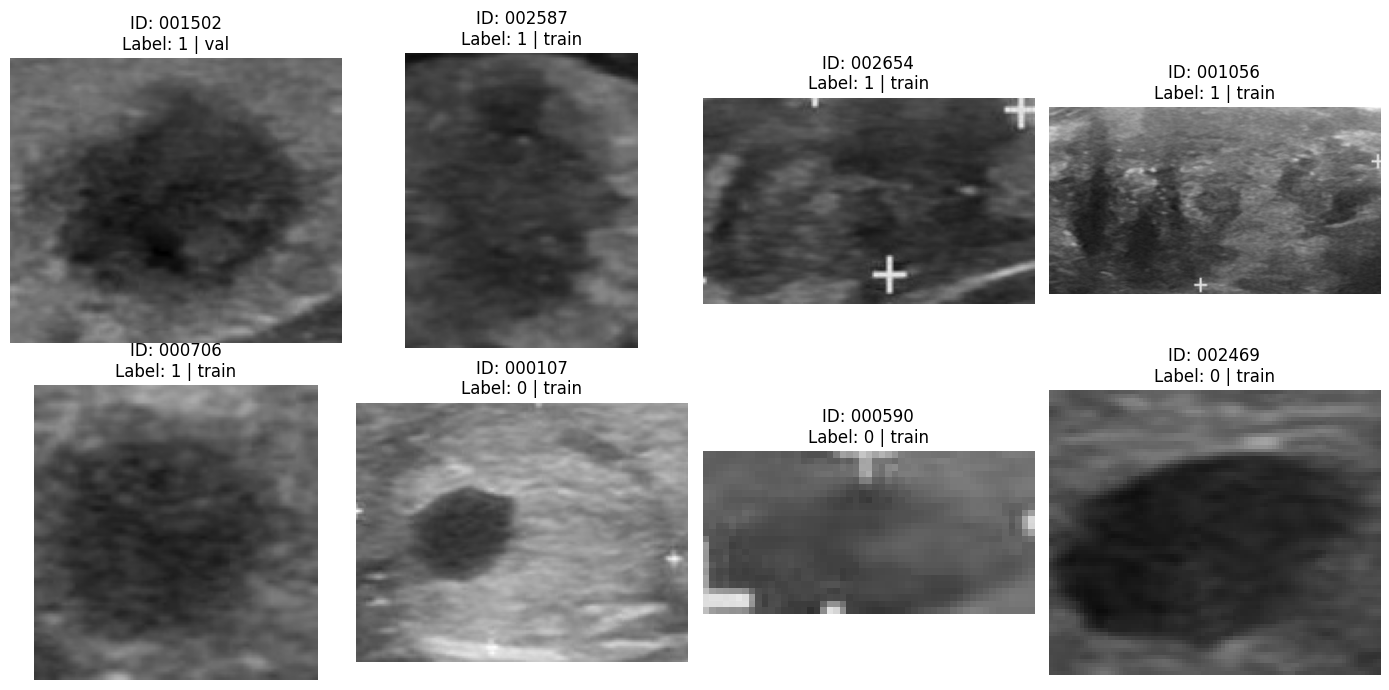

In [9]:

import random
import matplotlib.pyplot as plt
from PIL import Image

# Display 8 random ROI crops
sample_df = roi_df.sample(
    n=min(8, len(roi_df)),
    random_state=42
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    img = Image.open(row["roi_path"])
    ax.imshow(img)
    ax.set_title(
        f"ID: {int(row['image_id']):06d}\n"
        f"Label: {int(row['label'])} | {row['split']}"
    )
    ax.axis("off")

for ax in axes[len(sample_df):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

#Balancing the training data using augmentation

In [10]:

import os
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

# Load your existing ROI manifest
manifest_path = "/content/tn5000_roi/roi_manifest.csv"
output_dir = "/content/tn5000_roi_balanced"

df = pd.read_csv(manifest_path)

# Check required columns and image paths
required = {"image_id", "label", "split", "roi_path"}
assert required.issubset(df.columns), "Required columns are missing."
assert df["roi_path"].map(os.path.isfile).all(), "Some ROI images are missing."

# Separate the official splits
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("Original training distribution:")
print(train_df["label"].value_counts().sort_index())

# Determine the minority class and target count
counts = train_df["label"].value_counts().to_dict()
minority_label = min(counts, key=counts.get)
target_count = max(counts.values())
n_to_generate = target_count - counts[minority_label]

# Create separate output folders
for split in ["train", "val", "test"]:
    for label in [0, 1]:
        os.makedirs(
            os.path.join(output_dir, split, str(label)),
            exist_ok=True
        )

# Copy original images into the new folders
for split, split_df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    for _, row in split_df.iterrows():
        destination = os.path.join(
            output_dir, split, str(int(row["label"])),
            os.path.basename(row["roi_path"])
        )
        if not os.path.exists(destination):
            shutil.copy2(row["roi_path"], destination)

# Conservative augmentation for the minority training class only
augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(
        0.04, fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.08, 0.08),
        width_factor=(-0.08, 0.08),
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomContrast(0.08)
])

minority_df = train_df[
    train_df["label"] == minority_label
].reset_index(drop=True)

rng = np.random.default_rng(42)
augmented_rows = []

for i in range(n_to_generate):
    # Randomly select a minority-class training image
    source_index = int(rng.integers(0, len(minority_df)))
    row = minority_df.iloc[source_index]

    with Image.open(row["roi_path"]) as im:
        im = im.convert("RGB").resize((224, 224))
        image = np.asarray(im, dtype=np.float32) / 255.0

    image = augmenter(
        tf.expand_dims(image, axis=0),
        training=True
    )[0].numpy()

    image = np.clip(image * 255, 0, 255).astype(np.uint8)

    filename = f"aug_{i+1:05d}.jpg"
    save_path = os.path.join(
        output_dir, "train", str(minority_label), filename
    )
    Image.fromarray(image).save(save_path, quality=95)

    augmented_rows.append({
        "image_id": int(row["image_id"]),
        "label": int(minority_label),
        "split": "train",
        "roi_path": save_path,
        "source_roi_path": row["roi_path"],
        "is_augmented": True
    })

# Build a manifest for original and augmented samples
manifest_rows = []

for split, split_df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    for _, row in split_df.iterrows():
        manifest_rows.append({
            "image_id": int(row["image_id"]),
            "label": int(row["label"]),
            "split": split,
            "roi_path": os.path.join(
                output_dir, split, str(int(row["label"])),
                os.path.basename(row["roi_path"])
            ),
            "source_roi_path": row["roi_path"],
            "is_augmented": False
        })

manifest_rows.extend(augmented_rows)

balanced_df = pd.DataFrame(manifest_rows)
balanced_manifest_path = os.path.join(
    output_dir, "balanced_manifest.csv"
)
balanced_df.to_csv(balanced_manifest_path, index=False)

# Report results
print("\nBalanced training distribution:")
print(
    balanced_df[balanced_df["split"] == "train"]
    ["label"].value_counts().sort_index()
)

print("\nValidation distribution (unchanged):")
print(val_df["label"].value_counts().sort_index())

print("\nTest distribution (unchanged):")
print(test_df["label"].value_counts().sort_index())

print("\nNew images generated:", len(augmented_rows))
print("Saved manifest:", balanced_manifest_path)

Original training distribution:
label
0    1032
1    2468
Name: count, dtype: int64

Balanced training distribution:
label
0    2468
1    2468
Name: count, dtype: int64

Validation distribution (unchanged):
label
0    125
1    375
Name: count, dtype: int64

Test distribution (unchanged):
label
0    269
1    731
Name: count, dtype: int64

New images generated: 1436
Saved manifest: /content/tn5000_roi_balanced/balanced_manifest.csv


#Extract features using DenseNet121

We'll use ImageNet-pretrained DenseNet121 as a frozen feature extractor. It converts each 224×224 image into a 1,024-dimensional feature vector.

In [11]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input

# --------------------------------------------------
# 1. Load balanced manifest
# --------------------------------------------------
manifest_path = "/content/tn5000_roi_balanced/balanced_manifest.csv"
df = pd.read_csv(manifest_path)

IMG_SIZE = 224
BATCH_SIZE = 32

# --------------------------------------------------
# 2. Load pretrained DenseNet121
# include_top=False removes the original classifier.
# pooling="avg" creates 1024 features per image.
# --------------------------------------------------
base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

print("DenseNet121 loaded.")
print("Feature dimension:", base_model.output_shape[-1])

# --------------------------------------------------
# 3. Load and preprocess images in batches
# --------------------------------------------------
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

def make_dataset(frame):
    paths = frame["roi_path"].astype(str).values
    labels = frame["label"].astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

# --------------------------------------------------
# 4. Extract features separately for each split
# --------------------------------------------------
feature_dir = "/content/tn5000_densenet_features"
os.makedirs(feature_dir, exist_ok=True)

for split in ["train", "val", "test"]:
    split_df = df[df["split"] == split].reset_index(drop=True)

    dataset = make_dataset(split_df)

    features = base_model.predict(dataset, verbose=1)
    labels = split_df["label"].to_numpy(dtype=np.int32)

    np.save(
        os.path.join(feature_dir, f"X_{split}.npy"),
        features
    )
    np.save(
        os.path.join(feature_dir, f"y_{split}.npy"),
        labels
    )

    print(
        f"{split}: features={features.shape}, "
        f"labels={labels.shape}"
    )

print("\nFeature extraction completed.")
print("Saved to:", feature_dir)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
DenseNet121 loaded.
Feature dimension: 1024
155/155 ━━━━━━━━━━━━━━━━━━━━ 42s 169ms/step
train: features=(4936, 1024), labels=(4936,)
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 753ms/step
val: features=(500, 1024), labels=(500,)
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step
test: features=(1000, 1024), labels=(1000,)

Feature extraction completed.
Saved to: /content/tn5000_densenet_features


#Model training

Feature shapes:
Train: (4936, 1024) (4936,)
Validation: (500, 1024) (500,)

Training: SVM
Model                       SVM
Accuracy                  0.908
Balanced Accuracy          0.88
Macro F1               0.877981
Benign Recall             0.824
Malignant Recall          0.936
Malignant Precision    0.941019
ROC-AUC                0.949931

Classification report:
              precision    recall  f1-score   support

      Benign       0.81      0.82      0.82       125
   Malignant       0.94      0.94      0.94       375

    accuracy                           0.91       500
   macro avg       0.88      0.88      0.88       500
weighted avg       0.91      0.91      0.91       500


Training: Random Forest
Model                  Random Forest
Accuracy                       0.868
Balanced Accuracy           0.853333
Macro F1                    0.833347
Benign Recall                  0.824
Malignant Recall            0.882667
Malignant Precision         0.937677
ROC-AUC            

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Balanced Accuracy,Macro F1,Benign Recall,Malignant Recall,Malignant Precision,ROC-AUC
0,SVM,0.908,0.8800,0.8780,0.824,0.9360,0.9410,0.9499
1,LightGBM,0.884,0.8533,0.8477,0.792,0.9147,0.9295,0.9412
2,Extra Trees,0.880,0.8587,0.8456,0.816,0.9013,0.9363,0.9373
3,XGBoost,0.878,0.8520,0.8419,0.800,0.9040,0.9313,0.9417
4,Random Forest,0.868,0.8533,0.8333,0.824,0.8827,0.9377,0.9389
5,KNN,0.870,0.8040,0.8181,0.672,0.9360,0.8954,0.9105
6,Logistic Regression,0.854,0.8227,0.8117,0.760,0.8853,0.9171,0.8953


Comparison saved to: /content/tn5000_densenet_all_models_validation.csv


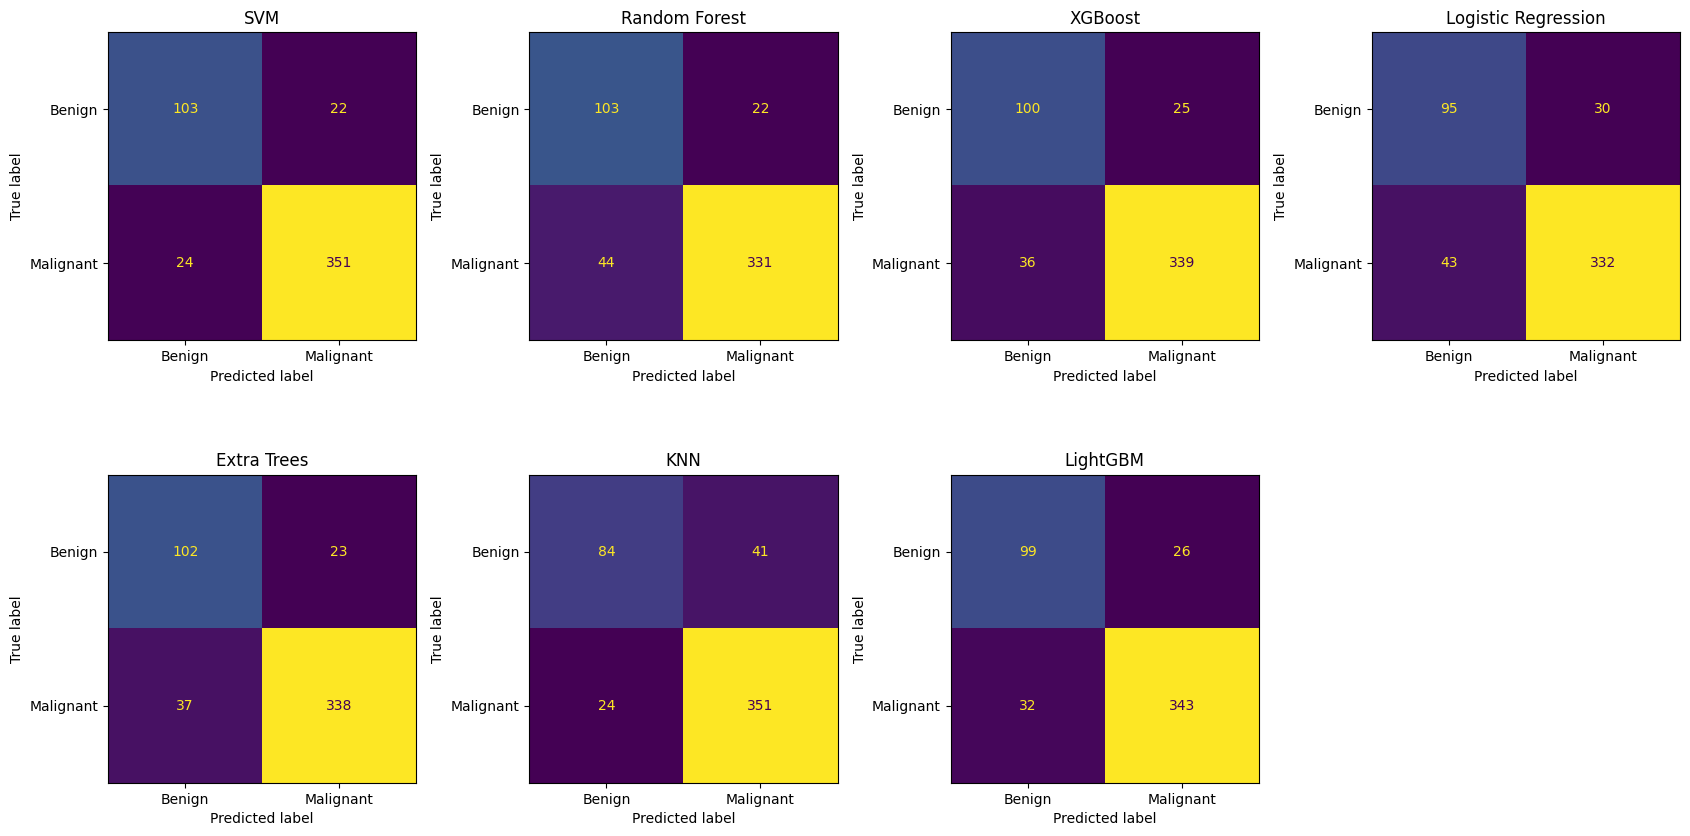

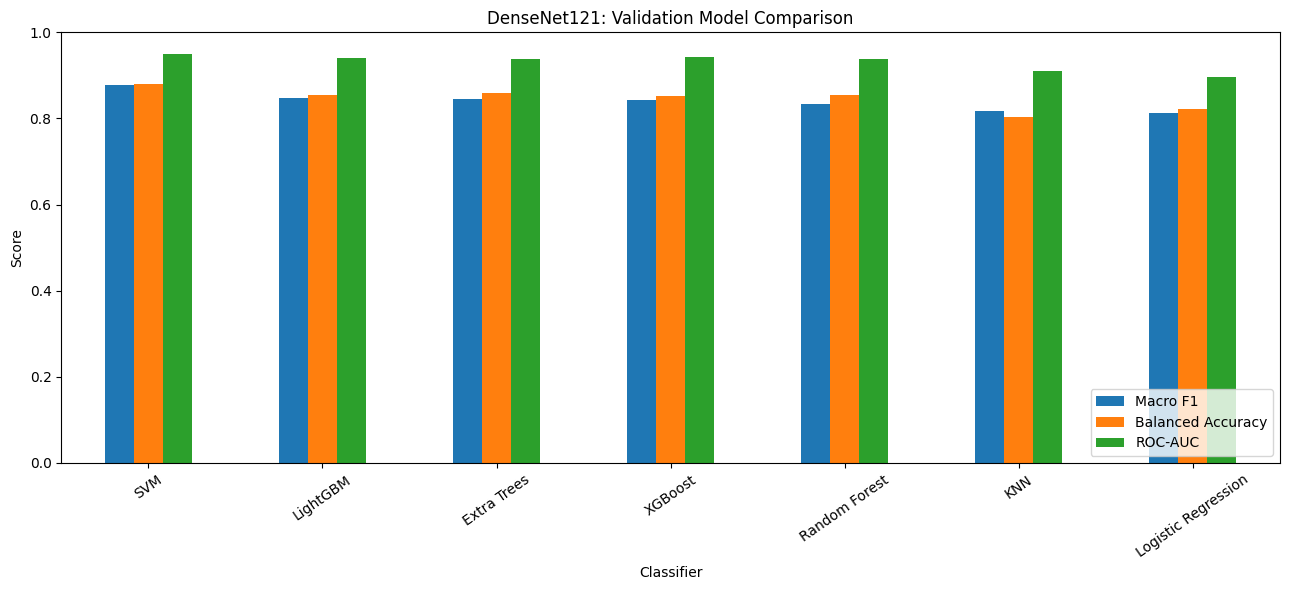


Completed all seven classifier experiments.


In [13]:

# ============================================================
# TN5000: DENSENET121 FEATURES + 7 CLASSIFIER COMPARISON
# Models: SVM, Random Forest, XGBoost, Logistic Regression,
#         Extra Trees, KNN, LightGBM
# ============================================================

%pip -q install xgboost lightgbm

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ------------------------------------------------------------
# 1. LOAD SAVED DENSENET121 FEATURES
# ------------------------------------------------------------

feature_dir = "/content/tn5000_densenet_features"

X_train = np.load(os.path.join(feature_dir, "X_train.npy"))
y_train = np.load(os.path.join(feature_dir, "y_train.npy"))

X_val = np.load(os.path.join(feature_dir, "X_val.npy"))
y_val = np.load(os.path.join(feature_dir, "y_val.npy"))

print("Feature shapes:")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}

# ------------------------------------------------------------
# 2. DEFINE ALL SEVEN CLASSIFIERS
# ------------------------------------------------------------

models = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        )
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=1.0,
            max_iter=2000,
            random_state=42
        )
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=7,
            weights="distance",
            n_jobs=-1
        )
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=15,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )
}

# ------------------------------------------------------------
# 3. TRAIN AND EVALUATE ON VALIDATION SET
# ------------------------------------------------------------

results = []
trained_models = {}
validation_predictions = {}

for name, model in models.items():

    print(f"\n{'=' * 50}")
    print("Training:", name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    y_score = model.predict_proba(X_val)[:, 1]

    trained_models[name] = model
    validation_predictions[name] = y_pred

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, y_pred
        ),
        "Macro F1": f1_score(
            y_val, y_pred, average="macro"
        ),
        "Benign Recall": recall_score(
            y_val, y_pred, pos_label=0,
            zero_division=0
        ),
        "Malignant Recall": recall_score(
            y_val, y_pred, pos_label=1,
            zero_division=0
        ),
        "Malignant Precision": precision_score(
            y_val, y_pred, pos_label=1,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, y_score)
    }

    results.append(result)

    print(pd.Series(result).to_string())
    print("\nClassification report:")
    print(classification_report(
        y_val,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    ))

# ------------------------------------------------------------
# 4. DISPLAY COMPLETE COMPARISON
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

print("\n\nFINAL VALIDATION COMPARISON")
display(results_df.round(4))

results_path = (
    "/content/tn5000_densenet_all_models_validation.csv"
)
results_df.to_csv(results_path, index=False)

print("Comparison saved to:", results_path)

# ------------------------------------------------------------
# 5. PLOT CONFUSION MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(17, 9))
axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    cm = confusion_matrix(
        y_val,
        validation_predictions[name],
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    ).plot(
        ax=axes[i],
        colorbar=False,
        values_format="d"
    )

    axes[i].set_title(name)

# Hide unused eighth panel
for i in range(len(trained_models), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. PLOT MODEL METRICS
# ------------------------------------------------------------

plot_df = results_df.set_index("Model")[
    ["Macro F1", "Balanced Accuracy", "ROC-AUC"]
]

plot_df.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1),
    rot=35
)

plt.title("DenseNet121: Validation Model Comparison")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("\nCompleted all seven classifier experiments.")

In [14]:
#cell to check whether your saved feature files are the same as before. It produces file hashes that you can save and compare across runs.
import os
import hashlib
import numpy as np

feature_dir = "/content/tn5000_densenet_features"

for filename in [
    "X_train.npy", "y_train.npy",
    "X_val.npy", "y_val.npy"
]:
    path = os.path.join(feature_dir, filename)

    if not os.path.exists(path):
        print(filename, "NOT FOUND")
        continue

    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    arr = np.load(path, mmap_mode="r")
    print(f"{filename}: shape={arr.shape}, SHA256={digest.hexdigest()}")

X_train.npy: shape=(4936, 1024), SHA256=c18f7acfd21f2d8beadf94ec4e0106c9c91e2ac95ecc260b64ce91a9f29b4679
y_train.npy: shape=(4936,), SHA256=4d00fdb7cda156012e5aa489054d27f8507394ba060b343369bbdca5d59c22a5
X_val.npy: shape=(500, 1024), SHA256=e9a4d45f06da291e5f4a02f442d47509094847e87d5635cc26541401432f5df8
y_val.npy: shape=(500,), SHA256=2e5c3e2b8e28a7540560adf27b3e9af298e66a73165b9426663f2ac337d3eb83


In [15]:
#running svm twice just to chech why the values are different from previous

import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

feature_dir = "/content/tn5000_densenet_features"

X_train = np.load(f"{feature_dir}/X_train.npy")
y_train = np.load(f"{feature_dir}/y_train.npy")
X_val = np.load(f"{feature_dir}/X_val.npy")
y_val = np.load(f"{feature_dir}/y_val.npy")

def train_svm():
    model = make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            probability=True,
            random_state=42
        )
    )
    model.fit(X_train, y_train)
    return model.predict(X_val)

pred1 = train_svm()
pred2 = train_svm()

print("Identical predictions:", np.array_equal(pred1, pred2))
print("Run 1 accuracy:", accuracy_score(y_val, pred1))
print("Run 2 accuracy:", accuracy_score(y_val, pred2))
print("Run 1 Macro-F1:", f1_score(y_val, pred1, average="macro"))
print("Run 2 Macro-F1:", f1_score(y_val, pred2, average="macro"))
print("Run 1 balanced accuracy:", balanced_accuracy_score(y_val, pred1))
print("Run 2 balanced accuracy:", balanced_accuracy_score(y_val, pred2))
print("Different predictions:", np.sum(pred1 != pred2))

Identical predictions: True
Run 1 accuracy: 0.908
Run 2 accuracy: 0.908
Run 1 Macro-F1: 0.8779814956285544
Run 2 Macro-F1: 0.8779814956285544
Run 1 balanced accuracy: 0.88
Run 2 balanced accuracy: 0.88
Different predictions: 0


Total validation errors: 46
Benign classified as malignant: 22
Malignant classified as benign: 24


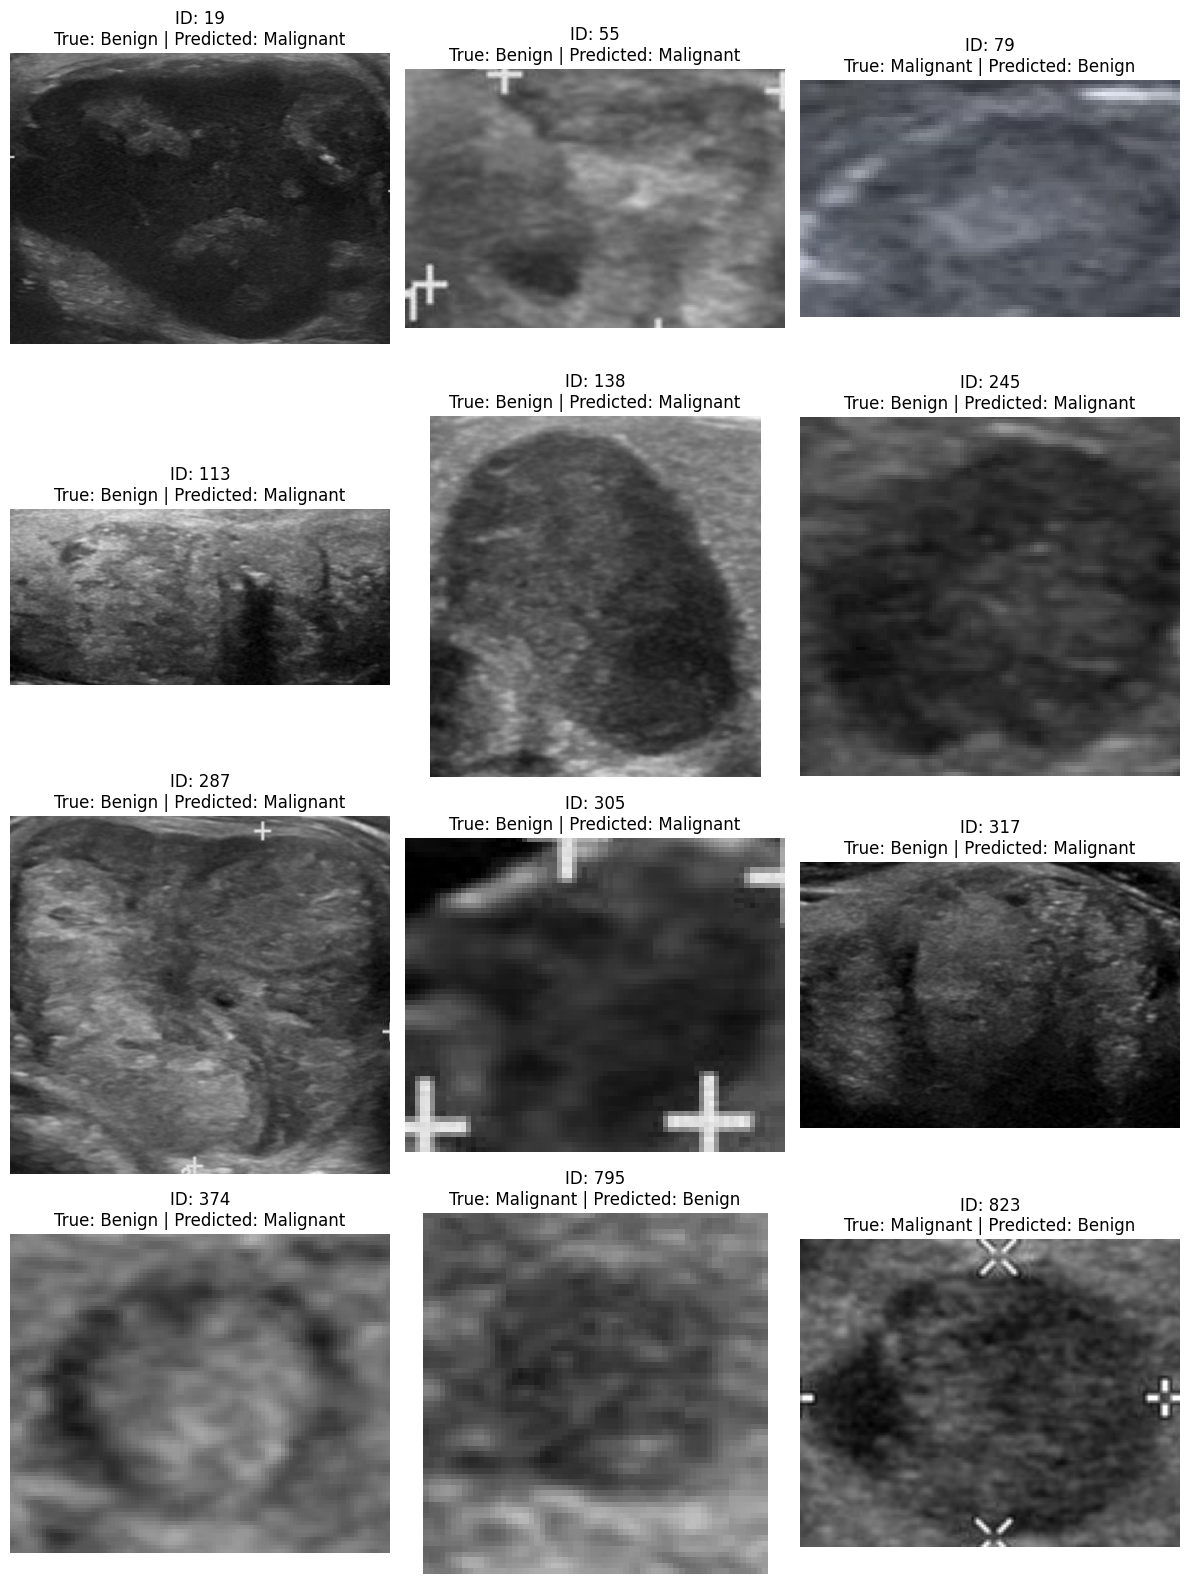

In [16]:
#Inspect the SVM mistakes
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

feature_dir = "/content/tn5000_densenet_features"
manifest_path = "/content/tn5000_roi_balanced/balanced_manifest.csv"

X_train = np.load(f"{feature_dir}/X_train.npy")
y_train = np.load(f"{feature_dir}/y_train.npy")
X_val = np.load(f"{feature_dir}/X_val.npy")
y_val = np.load(f"{feature_dir}/y_val.npy")

df = pd.read_csv(manifest_path)
val_df = df[df["split"] == "val"].reset_index(drop=True)

# Confirm the manifest matches the validation features
assert len(val_df) == len(y_val), (
    "Validation manifest and feature counts differ. "
    "Check the order used during feature extraction."
)
assert np.array_equal(val_df["label"].to_numpy(), y_val), (
    "Validation label order does not match y_val. "
    "Do not interpret image-level errors until alignment is fixed."
)

svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, probability=True, random_state=42)
)
svm.fit(X_train, y_train)
pred = svm.predict(X_val)

errors = np.where(pred != y_val)[0]
print("Total validation errors:", len(errors))
print("Benign classified as malignant:",
      np.sum((y_val == 0) & (pred == 1)))
print("Malignant classified as benign:",
      np.sum((y_val == 1) & (pred == 0)))

# Display up to 12 misclassified ROI crops
show_ids = errors[:12]
if len(show_ids) == 0:
    print("No validation errors found.")
else:
    cols = 3
    rows = int(np.ceil(len(show_ids) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, show_ids):
        row = val_df.iloc[idx]
        img_path = row["roi_path"]

        if os.path.exists(img_path):
            ax.imshow(Image.open(img_path).convert("RGB"))
            ax.set_title(
                f"ID: {row['image_id']}\n"
                f"True: {'Malignant' if y_val[idx] == 1 else 'Benign'} | "
                f"Predicted: {'Malignant' if pred[idx] == 1 else 'Benign'}"
            )
        else:
            ax.text(0.5, 0.5, f"Image not found:\n{img_path}",
                    ha="center", va="center")
        ax.axis("off")

    for ax in axes[len(show_ids):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

#Tune SVM to improve performance

Your current SVM uses C=1.0 and gamma='scale'. These are starting settings, not necessarily the best ones.

The following cell tests different settings using 5-fold cross-validation on training data only. It selects the configuration with the best Macro-F1.

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'svm__C': 10, 'svm__gamma': 0.001}
Best cross-validation Macro-F1: 0.9078

Tuned SVM — Validation Results
Accuracy: 0.902
Balanced Accuracy: 0.8733
Macro-F1: 0.8704
Benign Recall: 0.816
Malignant Recall: 0.9307
Malignant Precision: 0.9382
ROC-AUC: 0.9415

Classification Report:
              precision    recall  f1-score   support

      Benign       0.80      0.82      0.81       125
   Malignant       0.94      0.93      0.93       375

    accuracy                           0.90       500
   macro avg       0.87      0.87      0.87       500
weighted avg       0.90      0.90      0.90       500



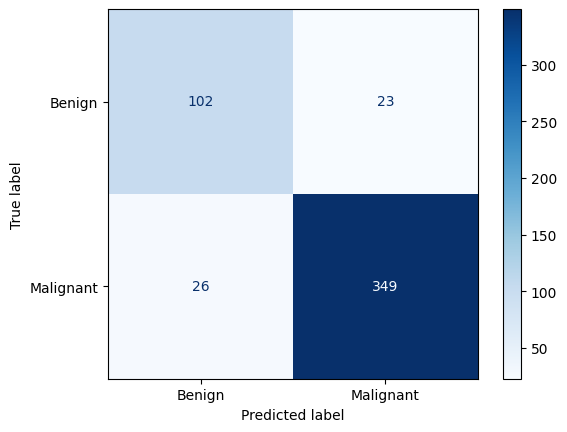

In [17]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", probability=False, random_state=42))
])

param_grid = {
    "svm__C": [0.1, 1, 10],
    "svm__gamma": ["scale", 0.001, 0.01]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation Macro-F1:", round(grid.best_score_, 4))

# Evaluate the tuned model on validation data
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    recall_score, precision_score, roc_auc_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

best_svm = grid.best_estimator_
val_pred = best_svm.predict(X_val)
val_scores = best_svm.decision_function(X_val)

print("\nTuned SVM — Validation Results")
print("Accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_val, val_pred), 4))
print("Macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 4))
print("Benign Recall:", round(recall_score(y_val, val_pred, pos_label=0), 4))
print("Malignant Recall:", round(recall_score(y_val, val_pred, pos_label=1), 4))
print("Malignant Precision:",
      round(precision_score(y_val, val_pred, pos_label=1), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, val_scores), 4))

print("\nClassification Report:")
print(classification_report(
    y_val, val_pred, target_names=["Benign", "Malignant"]
))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_val, val_pred),
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues")
plt.show()

#Test evaluation
As the tuning

Training features: (4936, 1024)
Test features: (1000, 1024)

========== FINAL TEST RESULTS ==========
Accuracy              : 0.8620 (86.20%)
Balanced Accuracy     : 0.8386 (83.86%)
Macro F1              : 0.8292 (82.92%)
Benign Recall         : 0.7881 (78.81%)
Malignant Recall      : 0.8892 (88.92%)
Malignant Precision   : 0.9194 (91.94%)
ROC-AUC               : 0.9211 (92.11%)

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Benign     0.7235    0.7881    0.7544       269
   Malignant     0.9194    0.8892    0.9040       731

    accuracy                         0.8620      1000
   macro avg     0.8215    0.8386    0.8292      1000
weighted avg     0.8667    0.8620    0.8638      1000

Confusion Matrix:
[[212  57]
 [ 81 650]]
Rows = actual classes; columns = predicted classes


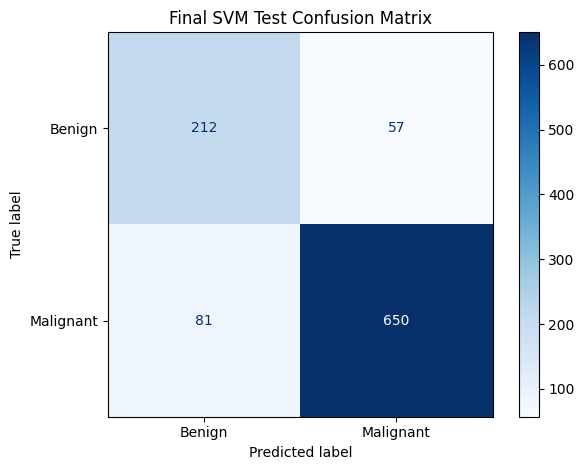

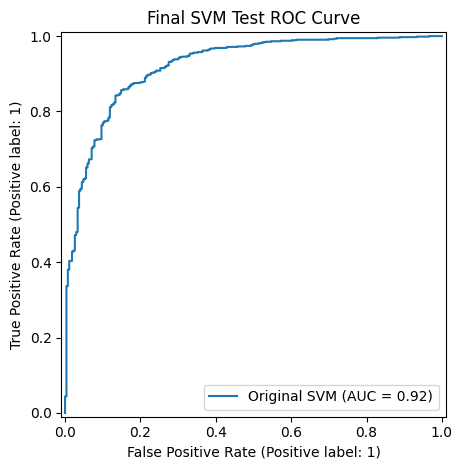


Results saved to: /content/tn5000_svm_final_test_results.csv


In [18]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 1. Load the saved DenseNet121 features
feature_dir = "/content/tn5000_densenet_features"

X_train = np.load(f"{feature_dir}/X_train.npy")
y_train = np.load(f"{feature_dir}/y_train.npy")

X_test = np.load(f"{feature_dir}/X_test.npy")
y_test = np.load(f"{feature_dir}/y_test.npy")

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

# 2. Train the ORIGINAL SVM selected using validation results
final_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    )
)

final_svm.fit(X_train, y_train)

# 3. Predict on the test set
y_pred = final_svm.predict(X_test)
y_prob = final_svm.predict_proba(X_test)[:, 1]

# 4. Calculate final test metrics
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Macro F1": f1_score(y_test, y_pred, average="macro"),
    "Benign Recall": recall_score(y_test, y_pred, pos_label=0),
    "Malignant Recall": recall_score(y_test, y_pred, pos_label=1),
    "Malignant Precision": precision_score(y_test, y_pred, pos_label=1),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

print("\n========== FINAL TEST RESULTS ==========")
for metric, value in results.items():
    print(f"{metric:22s}: {value:.4f} ({value * 100:.2f}%)")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    digits=4
))

# 5. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)
print("Rows = actual classes; columns = predicted classes")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", values_format="d")

plt.title("Final SVM Test Confusion Matrix")
plt.tight_layout()
plt.show()

# 6. ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Original SVM"
)
plt.title("Final SVM Test ROC Curve")
plt.tight_layout()
plt.show()

# 7. Save test metrics
results_df = pd.DataFrame(
    [{"Model": "DenseNet121 + SVM", **results}]
)

output_path = "/content/tn5000_svm_final_test_results.csv"
results_df.to_csv(output_path, index=False)

print("\nResults saved to:", output_path)

#saving the files of result

In [19]:
import os
import shutil

backup_dir = "/content/drive/MyDrive/TN5000_Project_Backup"
os.makedirs(backup_dir, exist_ok=True)

source = "/content/tn5000_svm_final_test_results.csv"
destination = os.path.join(
    backup_dir, "tn5000_svm_final_test_results.csv"
)

shutil.copy2(source, destination)

print("Saved to:", destination)

Saved to: /content/drive/MyDrive/TN5000_Project_Backup/tn5000_svm_final_test_results.csv


In [20]:
import os
import shutil

feature_dir = "/content/tn5000_densenet_features"
feature_backup = os.path.join(
    backup_dir, "tn5000_densenet_features"
)

shutil.copytree(
    feature_dir,
    feature_backup,
    dirs_exist_ok=True
)

print("Feature files saved to:", feature_backup)
print("Files:", os.listdir(feature_backup))

Feature files saved to: /content/drive/MyDrive/TN5000_Project_Backup/tn5000_densenet_features
Files: ['y_test.npy', 'X_train.npy', 'y_val.npy', 'X_test.npy', 'X_val.npy', 'y_train.npy']


In [21]:
# Save cropped ROI images and manifest
shutil.copytree(
    "/content/tn5000_roi",
    os.path.join(backup_dir, "tn5000_roi"),
    dirs_exist_ok=True
)

# Save balanced training data and manifest
shutil.copytree(
    "/content/tn5000_roi_balanced",
    os.path.join(backup_dir, "tn5000_roi_balanced"),
    dirs_exist_ok=True
)

print("ROI images and manifests backed up.")

ROI images and manifests backed up.


In [22]:
import joblib

model_path = os.path.join(
    backup_dir, "final_densenet121_svm.joblib"
)

joblib.dump(final_svm, model_path)

print("Model saved to:", model_path)

Model saved to: /content/drive/MyDrive/TN5000_Project_Backup/final_densenet121_svm.joblib


In [23]:
#To load the model in a future Colab session:
import joblib

final_svm = joblib.load(
    "/content/drive/MyDrive/TN5000_Project_Backup/"
    "final_densenet121_svm.joblib"
)

print("SVM model loaded successfully.")

SVM model loaded successfully.


In [24]:
import os

for root, dirs, files in os.walk(backup_dir):
    print(root, "| files:", len(files))

/content/drive/MyDrive/TN5000_Project_Backup | files: 2
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_densenet_features | files: 6
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi | files: 1
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/train | files: 0
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/train/1 | files: 2468
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/train/0 | files: 1032
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/val | files: 0
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/val/1 | files: 375
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/val/0 | files: 125
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/test | files: 0
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/test/1 | files: 731
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi/test/0 | files: 269
/content/drive/MyDrive/TN5000_Project_Backup/tn5000_roi_balanced | files: 1
/content/drive/MyDrive/TN5000_Project_Backup/t

#new feature model

In [25]:
import os
import pandas as pd

paths = {
    "Original ROI manifest": "/content/tn5000_roi/roi_manifest.csv",
    "Balanced manifest": "/content/tn5000_roi_balanced/balanced_manifest.csv",
}

for name, path in paths.items():
    print(f"\n{'=' * 15} {name} {'=' * 15}")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("File not found:", path)

print("\nROI folder examples:")
for root, dirs, files in os.walk("/content/tn5000_roi"):
    if files:
        print(root, "->", files[:3])
    if root.count(os.sep) >= 5:
        dirs[:] = []


=============== Original ROI manifest ===============
Shape: (5000, 14)
Columns: ['image_id', 'image_path', 'xml_path', 'label', 'xmin', 'ymin', 'xmax', 'ymax', 'image_width', 'image_height', 'split', 'roi_width', 'roi_height', 'roi_path']
 image_id                                                       image_path                                                          xml_path  label  xmin  ymin  xmax  ymax  image_width  image_height split  roi_width  roi_height                               roi_path
        1 /content/TN5000_extracted/TN5000_forReview/JPEGImages/000001.jpg /content/TN5000_extracted/TN5000_forReview/Annotations/000001.xml      0   223    90   286   131          718           500  test         64          42  /content/tn5000_roi/test/0/000001.jpg
        2 /content/TN5000_extracted/TN5000_forReview/JPEGImages/000002.jpg /content/TN5000_extracted/TN5000_forReview/Annotations/000002.xml      0   488    90   539   130          718           500 train         52          